# <span style="color:red"> Lecture 13: Silent Errors, Testing, and Debugging </span>

<font size="4">

In the previous class we:
- Sorted our mistakes into **syntax errors**, **runtime errors**, and **silent errors**
- Learned to read a **traceback** from the bottom up
- Kept our code alive with **`try`** and **`except`** - and saw how `except: pass` manufactures silent errors
- Asked the user a question with **`input()`**, and learned that it always hands back a string

<font size="4">

In this class we will:

- Meet the third kind of mistake head-on: code that runs perfectly and **lies to you**
- Use a **plot** to catch a bug that the printed output was hiding
- Make our code check itself with **`assert`**
- Write **tests**: small cases where we already know the right answer
- Put it all together into a repeatable **debugging recipe**

In [ ]:
# for convenience, put all import statements here
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random

<font size="4">

The usual 50 candidates, and two additional functions.

In [ ]:
lab_partners = {
    "Abed":      {"month": "March",     "day": 23, "year": 2007, "lab_skills": 3.24},
    "Britta":    {"month": "July",      "day": 14, "year": 1998, "lab_skills": 1.51},
    "Jeff":      {"month": "December",  "day": 8,  "year": 1990, "lab_skills": 0.51},
    "Shirley":   {"month": "January",   "day": 19, "year": 1990, "lab_skills": 6.72},
    "Annie":     {"month": "September", "day": 27, "year": 2007, "lab_skills": 6.72},
    "Troy":      {"month": "June",      "day": 5,  "year": 2007, "lab_skills": 3.66},
    "Pierce":    {"month": "December",  "day": 30, "year": 1962, "lab_skills": 0.58},
    "Chang":     {"month": "April",     "day": 17, "year": 1987, "lab_skills": 5.07},
    "Craig":     {"month": "August",    "day": 11, "year": 1985, "lab_skills": 0.37},
    "Magnitude": {"month": "February",  "day": 22, "year": 1983, "lab_skills": 4.34},
    "Garrett":   {"month": "October",   "day": 3,  "year": 2001, "lab_skills": 0.70},
    "Vicki":     {"month": "May",       "day": 29, "year": 2003, "lab_skills": 0.91},
    "Todd":      {"month": "March",     "day": 16, "year": 1997, "lab_skills": 9.99},
    "Starburns": {"month": "July",      "day": 7,  "year": 1982, "lab_skills": 8.27},
    "Neil":      {"month": "January",   "day": 25, "year": 1998, "lab_skills": 1.24},
    "Leonard":   {"month": "November",  "day": 13, "year": 1993, "lab_skills": 2.23},
    "Willy":     {"month": "September", "day": 4,  "year": 1981, "lab_skills": 6.27},
    "Pavel":     {"month": "June",      "day": 21, "year": 1980, "lab_skills": 9.48},
    "Quendra":   {"month": "December",  "day": 9,  "year": 1982, "lab_skills": 5.77},
    "Rich":      {"month": "April",     "day": 28, "year": 1986, "lab_skills": 3.97},
    "Duncan":    {"month": "August",    "day": 15, "year": 1987, "lab_skills": 9.76},
    "Hickey":    {"month": "February",  "day": 6,  "year": 1996, "lab_skills": 0.47},
    "Buzz":      {"month": "October",   "day": 24, "year": 1999, "lab_skills": 8.58},
    "Rachel":    {"month": "May",       "day": 18, "year": 1980, "lab_skills": 2.90},
    "Ian":       {"month": "March",     "day": 12, "year": 1997, "lab_skills": 1.44},
    "Elroy":     {"month": "July",      "day": 30, "year": 1986, "lab_skills": 1.18},
    "Frankie":   {"month": "November",  "day": 2,  "year": 2002, "lab_skills": 3.08},
    "Natalie":   {"month": "September", "day": 20, "year": 2000, "lab_skills": 8.16},
    "Owen":      {"month": "June",      "day": 11, "year": 2002, "lab_skills": 1.81},
    "Paula":     {"month": "December",  "day": 26, "year": 1997, "lab_skills": 5.82},
    "Quinn":     {"month": "April",     "day": 1,  "year": 1993, "lab_skills": 6.39},
    "Roger":     {"month": "August",    "day": 17, "year": 1987, "lab_skills": 3.72},
    "Sara":      {"month": "February",  "day": 8,  "year": 1994, "lab_skills": 5.48},
    "Tim":       {"month": "October",   "day": 22, "year": 1998, "lab_skills": 0.63},
    "Uma":       {"month": "May",       "day": 14, "year": 1988, "lab_skills": 0.60},
    "Victor":    {"month": "January",   "day": 29, "year": 2005, "lab_skills": 2.06},
    "Wendy":     {"month": "July",      "day": 5,  "year": 2007, "lab_skills": 6.80},
    "Xavier":    {"month": "March",     "day": 19, "year": 1980, "lab_skills": 4.28},
    "Yolanda":   {"month": "November",  "day": 10, "year": 2004, "lab_skills": 3.14},
    "Zara":      {"month": "September", "day": 3,  "year": 2005, "lab_skills": 5.86},
    "Alex":      {"month": "June",      "day": 27, "year": 1985, "lab_skills": 4.53},
    "Blake":     {"month": "December",  "day": 16, "year": 2002, "lab_skills": 3.00},
    "Casey":     {"month": "April",     "day": 7,  "year": 1993, "lab_skills": 7.94},
    "Dana":      {"month": "August",    "day": 23, "year": 1990, "lab_skills": 6.99},
    "Eli":       {"month": "February",  "day": 18, "year": 1988, "lab_skills": 2.44},
    "Fiona":     {"month": "October",   "day": 12, "year": 1984, "lab_skills": 5.74},
    "George":    {"month": "May",       "day": 25, "year": 1986, "lab_skills": 5.25},
    "Hana":      {"month": "January",   "day": 6,  "year": 2004, "lab_skills": 8.75},
    "Ivan":      {"month": "July",      "day": 21, "year": 1990, "lab_skills": 7.29},
    "Julia":     {"month": "March",     "day": 15, "year": 1983, "lab_skills": 2.88},
}

months = ["January", "February", "March", "April",
          "May", "June", "July", "August",
          "September", "October", "November", "December"]

print(len(lab_partners), "potential lab partners")

In [ ]:
# Labeled bar plot function from Lecture 11, Section III

def labeled_bar_plot(x_vals, heights, xlabel, ylabel, title):
    plt.bar(x = x_vals, height = heights)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.show()

In [ ]:
# Lab partner trial function

def run_one_trial(N):

    # shuffle
    interview_order = list(lab_partners.keys())
    random.shuffle(interview_order)

    # benchmark phase
    best_of_first_N = 0
    for position in range(N):
        name = interview_order[position]
        skill = lab_partners[name]["lab_skills"]
        if skill > best_of_first_N:
            best_of_first_N = skill

    # selection phase
    chosen_name = interview_order[-1]
    for position in range(N, len(interview_order)):
        name = interview_order[position]
        skill = lab_partners[name]["lab_skills"]
        if skill > best_of_first_N:
            chosen_name = name
            break

    chosen_skill = lab_partners[chosen_name]["lab_skills"]

    return chosen_name, chosen_skill

## <span style="color:red"> I. Errors that do not raise an error </span>

<font size = "4">

A syntax error stops you before you start. A runtime error stops you in the middle. Both of them are, in a real sense, *doing you a favor*: they hand you a line number and an error type, and last class you learned how to read them.

A **silent error** gives you none of that. The cell runs. It prints. The answer is wrong.

Python is not going to help you here. Nobody is. You have to build the alarm yourself, and the rest of this notebook is about how.

### Example 1: comparing text instead of numbers

<font size = "4">

Last class we learned that `input()` always hands back a **string**. Suppose three candidates typed their own assessment scores in, and we forgot to convert.

**Predict the output of the next cell before you run it.**

In [5]:
print(9.99 > 10.50)       # as numbers

print("9.99" > "10.50")   # as text

False
True


<font size = "4">

**Side note:** All characters in Python are ordered. You can view how they are ordered by using the `ord` function:

In [ ]:
print(ord("9"))
print(ord("1"))

print(ord("a"))
print(ord("B"))

# so "1" < "9" < "B" < "a"
# because 49 < 57 < 66 < 97

<font size = "4">

Python compared those two strings the way it compares any two words - character by character, the way a dictionary orders things. That is exactly the comparison you did in Lecture 6, Exercise 9, when you tested whether your name was "greater than" your classmate's. The character `"9"` comes after the character `"1"`, so `"9.99"` wins and the comparison stops right there.

Now watch that ruin a running maximum.

In [6]:
typed_scores = ["9.99", "8.27", "10.50", "6.72"]

best = "0"
for score in typed_scores:
    if score > best:
        best = score

print("The best score typed in was", best)

The best score typed in was 9.99


<font size = "4">

No warning. No `nan`. A perfectly sensible-looking sentence with the wrong number in it.

This is the bug your syllabus warns about in Week 2, where `"10"` sorts before `"2"`. It is one of the most common silent errors in all of data analysis, and it happens any time a number arrives as text - from `input()`, from a spreadsheet, from a web page.

### Example 2: updating the wrong counter

<font size = "4">

Here is a small calculation. Read it carefully, then run it.

In [8]:
# What fraction of our candidates have lab skills above 8?

num_strong = 0
num_checked = 0

for name in list(lab_partners.keys()):
    skill = lab_partners[name]["lab_skills"]

    
    if skill > 8:
        num_strong = num_strong + 1
        
    num_checked = num_checked + 1

print("Number of strong candidates:", num_strong)
print("Fraction of the class that is strong:", num_strong / num_checked)

Number of strong candidates: 7
Fraction of the class that is strong: 0.14


<font size = "4">

The fraction is `1.0`. Every single candidate is strong.

Nobody has to check the code to know that is wrong. **A probability of exactly 1.0 is a claim about the world, and this one is obviously false** - we have been looking at Craig (0.37) and Jeff (0.51) for four lectures.

That is the single most valuable habit in this entire class:

> **Before you ask "is my code right?", ask "could this answer possibly be right?"**

Probabilities live between 0 and 1. Counts are never negative and never exceed the number of things you counted. Lab skills are out of 10. An average sits somewhere between the smallest and the largest value. Any answer that breaks one of those is a bug, and you knew it before you read a single line.

## <span style="color:red"> II. A plot that looks wrong </span>

<font size = "4">

Numbers are easy to skim past. Pictures are much harder to ignore, and that is the real reason this course plots things constantly instead of saving it for the end.

Let's go back to the birthday problem from Lecture 7. Same room of people, same simplifying assumption that every month has 30 days, so there are $12 \times 30 = 360$ possible birthdays. This time we will write it as two functions, because after Lectures 10 and 11 we can.

In [9]:
def one_birthday_trial(room_size):
    # give each person in the room a random birthday
    room = []
    for k in range(room_size):
        month = random.choice(months)
        day = random.randint(1, 30)
        room.append([month, day])

    # check every pair of people for a match
    for i in range(room_size):
        for j in range(i, room_size):
            if room[i][0] == room[j][0] and room[i][1] == room[j][1]:
                return True

    return False


def estimate_probability(room_size, num_trials):
    num_matches = 0

    for trial in range(num_trials):
        if one_birthday_trial(room_size):
            num_matches = num_matches + 1

    return num_matches / num_trials

<font size = "4">

Both functions run without complaint. Let's use them exactly the way Lecture 7, Exercise 8 asked: estimate the probability for several room sizes, and draw the bar plot.

Room sizes: [2, 5, 10, 25, 40, 50]
Estimates : [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


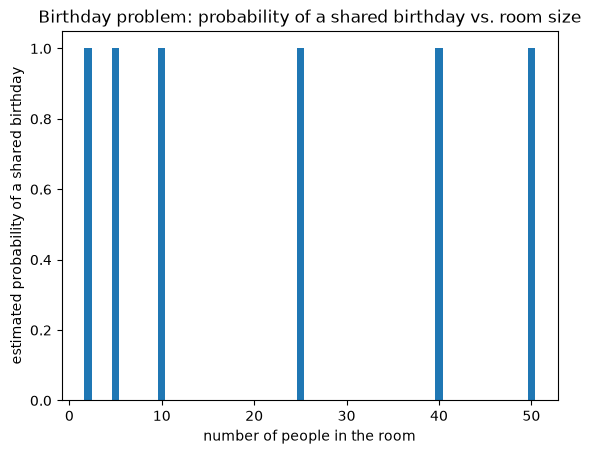

In [10]:
room_sizes = [2, 5, 10, 25, 40, 50]
estimates = []

for size in room_sizes:
    estimates.append(estimate_probability(size, 500))

print("Room sizes:", room_sizes)
print("Estimates :", estimates)

labeled_bar_plot(x_vals = room_sizes, heights = estimates,
    xlabel = "number of people in the room",
    ylabel = "estimated probability of a shared birthday",
    title = "Birthday problem: probability of a shared birthday vs. room size")

<font size = "4">

**Stop and look at that picture.**

Six bars, all exactly the same height, all at 1.00. Now read the leftmost bar back to yourself as an English sentence:

> *"If two people are in a room, the probability that they share a birthday is 100%."*

We know that number. It is $\frac{1}{360}$, or about 0.003. The code raised nothing, printed nothing unusual, and produced a figure you could paste into a report.

<font size = "4">

It is worth being precise about what the plot just did for us, because it is the whole argument for plotting early.

The printed list said `[1.0, 1.0, 1.0, 1.0, 1.0, 1.0]`. That is the same information. But six identical numbers in a row is easy to glance at and move on from, while a **flat wall of bars where you were expecting a rising curve** is impossible to move on from. You already had a picture in your head of what the answer should look like - rising, crossing 50% somewhere in the middle - and the plot let your eyes do the comparison for you in about a quarter of a second.

Plot early, plot often, and *know what shape you are expecting before you look*.

### Finding it

<font size = "4">

Now let's actually locate the bug. The most useful move, almost always, is: **make the failing case as small as you can possibly make it.**

50 people is 1225 pairs. Nobody can hold that in their head. What is the smallest room we can reason about with no effort at all?

In [11]:
# One person cannot share a birthday with anybody. There is nobody else in the room.

print(one_birthday_trial(1))

True


<font size = "4">

`True`.

That is the entire bug, right there, in a case small enough to check on your fingers. There is no pair at all in a room of one person, and yet our function found a match. So the pair-checking loops must be matching somebody **with themselves**.

Let's confirm it by printing out exactly which pairs the loops visit for a room of 3.

In [12]:
room_size = 3

for i in range(room_size):
    for j in range(i, room_size):
        print("comparing person", i, "with person", j)

comparing person 0 with person 0
comparing person 0 with person 1
comparing person 0 with person 2
comparing person 1 with person 1
comparing person 1 with person 2
comparing person 2 with person 2


<font size = "4">

Six comparisons - and three of them are a person against themselves.

There are only three genuine pairs in a room of three people: (0,1), (0,2), and (1,2). The instructions in Lecture 7, Exercise 5 said to use `range(i + 1, room_size)`, "so we never compare a person to themselves or check the same pair twice." That `+ 1` was not decoration. It was doing all the work.

In [13]:
# The fix: one character.

def one_birthday_trial(room_size):
    room = []
    for k in range(room_size):
        month = random.choice(months)
        day = random.randint(1, 30)
        room.append([month, day])

    for i in range(room_size):
        for j in range(i + 1, room_size):
            if room[i][0] == room[j][0] and room[i][1] == room[j][1]:
                return True

    return False

Room sizes: [2, 5, 10, 25, 40, 50]
Estimates : [0.0, 0.036, 0.13, 0.596, 0.876, 0.984]


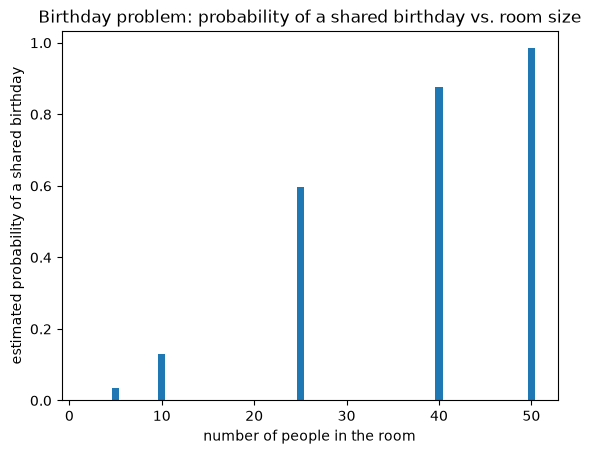

In [14]:
estimates = []

for size in room_sizes:
    estimates.append(estimate_probability(size, 500))

print("Room sizes:", room_sizes)
print("Estimates :", estimates)

labeled_bar_plot(x_vals = room_sizes, heights = estimates,
    xlabel = "number of people in the room",
    ylabel = "estimated probability of a shared birthday",
    title = "Birthday problem: probability of a shared birthday vs. room size")

<font size = "4">

Now the picture makes sense. The bar for two people is so short you may not see it at all (with 500 trials and a true probability near 0.003, it is often exactly zero), and from there it climbs steeply, crossing one half somewhere around 25 people, and flattening out as it approaches 1. That last part is the reason the birthday problem is famous, and it is also the reason the broken version was able to hide - at 50 people the *correct* answer really is about 0.97, so the rightmost bar barely moved when we fixed it.

**The bug was easiest to see in the case we cared about least.**

## <span style="color:red"> III. Making the code check itself with `assert` </span>

<font size = "4">

We caught that bug because somebody happened to look at the plot and happened to remember what the answer should be. That is luck, and luck does not scale to a 15-week project.

So let's write the check down. First, using only tools from Lecture 6:

In [15]:
# Version 1: check it by hand

p = estimate_probability(1, 500)

if p == 0:
    print("OK: a room of 1 person never has a match")
else:
    print("PROBLEM: a room of 1 person reported a match!")

OK: a room of 1 person never has a match


<font size = "4">

That works. But it is four lines, it needs a fresh variable, and - worst of all - it only helps if somebody *reads the output*. In a notebook with 60 cells, nobody reads the output.

Python has a one-line version that refuses to be ignored:

```python
    assert <something that should be True>, "message if it is not"
```

The behaviour is deliberately lopsided:

- If the condition is `True`, `assert` does **absolutely nothing**. No output. The line just goes by.
- If the condition is `False`, Python stops immediately with an `AssertionError` and shows your message.

In other words, `assert` **converts a silent error into a runtime error** - and we spent all of last class learning how to handle those.

In [16]:
# With the fixed function, this passes. Notice that it prints nothing at all.

assert estimate_probability(1, 500) == 0, "a room of 1 person cannot have a shared birthday"

print("check passed")

check passed


In [17]:
# Here is the same assertion against the broken version. This cell fails on purpose.

def one_birthday_trial_broken(room_size):
    room = []
    for k in range(room_size):
        room.append([random.choice(months), random.randint(1, 30)])

    for i in range(room_size):
        for j in range(i, room_size):                 # the old bug
            if room[i][0] == room[j][0] and room[i][1] == room[j][1]:
                return True
    return False



bad_results = 0
for trial in range(500):
    if one_birthday_trial_broken(1) == True:
        bad_results = bad_results + 1

assert bad_results == 0, "a room of 1 person cannot have a shared birthday"

AssertionError: a room of 1 person cannot have a shared birthday

<font size = "4">

Compare that message to the plot. The plot said "something in this analysis is wrong somewhere." The assertion said "*a room of 1 person cannot have a shared birthday*," and it said it on the exact line where the claim was broken.

### Where to put assertions

<font size = "4">

Two places are worth the keystrokes:

- At the **top** of a function, check that what you were handed makes sense. (A **precondition**: "for this question to mean anything, the following must be true.")
- At the **bottom**, check that what you are about to hand back makes sense. (A **postcondition**.)

In [ ]:
def estimate_probability(room_size, num_trials):

    # preconditions: what has to be true for this question to make any sense
    assert room_size >= 1, f"a room needs at least 1 person, you tried {room_size}"
    assert num_trials >= 1, "cannot average over 0 trials"

    num_matches = 0
    for trial in range(num_trials):
        if one_birthday_trial(room_size):
            num_matches = num_matches + 1

    p = num_matches / num_trials

    # postcondition: whatever happened above, this had better be a probability
    assert p >= 0 and p <= 1, "a probability must be between 0 and 1"

    return p


print(estimate_probability(25, 500))

In [ ]:
# Both of these now fail immediately, with messages that say what you did wrong.
# Run them one at a time.

# print(estimate_probability(25, 0))

print(estimate_probability(-32, 500))

<font size = "4">

Notice what that second precondition just did. Without it, `num_trials = 0` produced a `ZeroDivisionError` from Lecture 12 - a message about arithmetic, several lines away from the actual mistake. With it, you get a message about *trials*, on the first line of the function.

That is the general principle, and it is worth writing down:

> **Fail as close to the mistake as you can.**

The further your program travels between making a mistake and noticing it, the more work it is to find. An assertion that fires on line 3 costs you a minute. The same mistake, discovered in a plot on the last page of your final project, costs you an afternoon.

### `assert` or `try` / `except`? Whose fault is it?

<font size = "4">

These two tools look similar and are for opposite situations. The question to ask is: **whose mistake is this?**

| Situation | Tool | Why |
|---|---|---|
| The user typed "twenty" instead of 20 | `try` / `except` | Not a bug. People do that. Ask again. |
| A name on a sign-up sheet is misspelled | `try` / `except` | Not a bug. Skip it and say so. |
| My roster has 47 people in it and it should have 50 | `assert` | That is a bug. Stop. |
| My function returned a probability of 1.4 | `assert` | That is a bug. Stop. |

`try` / `except` is for things the world does to you. `assert` is for things you believe about your own code. Never use `assert` to validate user input - you will just crash on somebody for typing a letter.

## <span style="color:red"> IV. Testing: cases where you already know the answer </span>

<font size = "4">

An assertion checks a *property* ("this is a probability"). A **test** checks a specific answer that you worked out **independently of the code** - by hand, by mathematics, or by a completely different method.

That last phrase is the whole game. A test you derived by running the code is not a test; it is a photograph of the bug.

Good test cases come from three places:

**1. Cases small enough to do in your head.** A room of 1 person.

**2. Cases that mathematics settles for you.** In a 360-day year, a room of 361 people *must* contain a shared birthday - there are only 360 birthdays to go around, so somebody has to double up. (This is called the pigeonhole principle.)

**3. Edges.** N = 0 and N = 49 in the lab partner problem; the first and last element of a list.

In [18]:
# Two tests for one_birthday_trial. Neither depends on which random birthdays came up.

assert one_birthday_trial(1) == False, "a room of 1 cannot contain a match"
assert one_birthday_trial(361) == True, "361 people in a 360-day year MUST contain a match"

print("one_birthday_trial passed both tests")

one_birthday_trial passed both tests


<font size = "4">

Look at what makes those two good. Our function is full of `random.choice` and `random.randint`, and yet **neither test can fail by bad luck**. A room of 1 has no pairs regardless of the draw. A room of 361 overflows the calendar regardless of the draw.

That matters more than it might seem. A test that passes only *most* of the time is worse than no test at all, because you will very quickly learn to shrug and re-run it - and then one day it will be failing for a real reason and you will shrug at that too.

### Testing something that really is random

<font size = "4">

Sometimes there is no way around the randomness, and then we test the *average* instead - carefully.

Take `run_one_trial(0)`. With N = 0 there is no benchmark phase at all, so the benchmark stays at 0, and the very first candidate we meet beats it. In other words, **N = 0 is just "pick a candidate at random."** So over many trials, the average chosen skill should land near the average skill of the whole class.

Two cautions, both of which we have already run into:

- Lecture 6, Exercise 12 taught us never to compare floating-point numbers with `==`. We check that the difference is *small* instead.
- The more trials we run, the smaller that difference gets. 1000 trials is enough here.

In [ ]:
# The average skill of the whole class

all_skills = []
for name in list(lab_partners.keys()):
    all_skills.append(lab_partners[name]["lab_skills"])

class_average = np.mean(all_skills)

# The average outcome of the N = 0 strategy
results = []
for trial in range(1000):
    chosen_name, chosen_skill = run_one_trial(0)
    results.append(chosen_skill)

strategy_average = np.mean(results)

print("Average skill of the whole class:", round(class_average, 2))
print("Average skill chosen by N = 0   :", round(strategy_average, 2))

# np.abs is the absolute value, so we do not care which of the two is larger
difference = np.abs(strategy_average - class_average)
assert difference < 0.5, "N = 0 should behave like choosing a candidate at random"

print("passed")

### Make your functions testable

<font size = "4">

Here is a bug that neither the plot nor any of the tests above can catch.

`run_one_trial` has a `break` in the selection loop. Delete it, and the function no longer implements our strategy at all: instead of stopping at the **first** candidate who beats the benchmark, it keeps going and ends up with the **last** one - which is impossible in the real game, because you cannot go back to somebody you already passed on.

Run the two cells below.

In [ ]:
def run_one_trial_nobreak(N):

    interview_order = list(lab_partners.keys())
    random.shuffle(interview_order)

    best_of_first_N = 0
    for position in range(N):
        skill = lab_partners[interview_order[position]]["lab_skills"]
        if skill > best_of_first_N:
            best_of_first_N = skill

    chosen_name = interview_order[-1]
    for position in range(N, len(interview_order)):
        skill = lab_partners[interview_order[position]]["lab_skills"]
        if skill > best_of_first_N:
            chosen_name = interview_order[position]
            # the break is gone

    return chosen_name, lab_partners[chosen_name]["lab_skills"]


correct = []
broken = []
for trial in range(1000):
    correct.append(run_one_trial(8)[1])
    broken.append(run_one_trial_nobreak(8)[1])

print("average with the break   :", round(np.mean(correct), 2))
print("average without the break:", round(np.mean(broken), 2))

<font size = "4">

The two averages come out within a tenth or two of each other. Re-run the cell a few times: sometimes the broken one is higher, sometimes the correct one is, and there is no pattern to it. If you drew the bar chart from Lecture 11 with the broken function you would not be able to tell the difference, and yet the function is simulating **a strategy that is against the rules**.

Why can no test we have written catch it? Because `chosen_skill` is the only thing coming out of the function, and the bug is not about *who* we chose - it is about *when we stopped*. The information simply is not in the return value.

**So put it in the return value.** A function is only as testable as the evidence it hands back.

In [ ]:
def run_one_trial_v2(N):

    interview_order = list(lab_partners.keys())
    random.shuffle(interview_order)

    best_of_first_N = 0
    for position in range(N):
        skill = lab_partners[interview_order[position]]["lab_skills"]
        if skill > best_of_first_N:
            best_of_first_N = skill

    chosen_position = len(interview_order) - 1
    for position in range(N, len(interview_order)):
        skill = lab_partners[interview_order[position]]["lab_skills"]
        if skill > best_of_first_N:
            chosen_position = position
            break

    chosen_name = interview_order[chosen_position]

    # now we can return WHEN we stopped, not just who we got
    return chosen_name, lab_partners[chosen_name]["lab_skills"], chosen_position

In [ ]:
# The SAME function with the break deleted -- our bug from a moment ago,
# but now it hands back the position too.

def run_one_trial_v2_nobreak(N):

    interview_order = list(lab_partners.keys())
    random.shuffle(interview_order)

    best_of_first_N = 0
    for position in range(N):
        skill = lab_partners[interview_order[position]]["lab_skills"]
        if skill > best_of_first_N:
            best_of_first_N = skill

    chosen_position = len(interview_order) - 1
    for position in range(N, len(interview_order)):
        skill = lab_partners[interview_order[position]]["lab_skills"]
        if skill > best_of_first_N:
            chosen_position = position
            # the break is gone

    chosen_name = interview_order[chosen_position]

    return chosen_name, lab_partners[chosen_name]["lab_skills"], chosen_position


# Run each version 10 times with N = 0, and collect BOTH pieces of evidence.

correct_skills = []
correct_positions = []
broken_skills = []
broken_positions = []

for trial in range(10):
    name, skill, position = run_one_trial_v2(0)
    correct_skills.append(skill)
    correct_positions.append(position)

    name, skill, position = run_one_trial_v2_nobreak(0)
    broken_skills.append(skill)
    broken_positions.append(position)

print("WHO we ended up with:")
print("   correct:", correct_skills)
print("   broken :", broken_skills)
print()
print("WHEN we stopped:")
print("   correct:", correct_positions)
print("   broken :", broken_positions)

<font size = "4">

That is three return values instead of two. Lecture 10 only ever showed us two, but nothing changes: separate them with commas on the way out, and unpack them into three variables on the way in.

In [ ]:
# The test. With N = 0 the benchmark is 0, and everybody beats 0,
# so a correct implementation MUST stop at position 0 every single time.

for trial in range(20):
    name, skill, position = run_one_trial_v2(0)
    assert position == 0, "with N = 0 you must stop at the very first candidate"

print("passed: N = 0 always stops immediately")

In [ ]:
# Now the assertion has something to bite on. This cell fails on purpose.

for trial in range(10):
    name, skill, position = run_one_trial_v2_nobreak(0)
    assert position == 0, "with N = 0 you must stop at the very first candidate"

## <span style="color:red"> V. A debugging recipe </span>

<font size = "4">

Debugging feels like a talent. It is a procedure. Here is the one we just used, written down.

**1. Decide what the right answer looks like, first.** "My code doesn't work" is not a debuggable statement. "This should be near 0.5 and it is 1.0" is. If you cannot say what you expected, that is the bug you have to fix first.

**2. Make the failing case as small as possible.** A room of 1 instead of 50. Three candidates instead of fifty. One trial instead of a thousand. A bug you can hold in your head is a bug you can find.

**3. Change one thing at a time**, and re-check after each change. Editing four lines at once is how a one-hour bug becomes a three-hour bug.

**4. Look at the middle.** Print a variable halfway through. If it is right, the bug is below it; if it is wrong, the bug is above it. Then repeat on whichever half is left. Each check throws away half of the suspects, so even a hundred lines only takes about seven checks.

**5. Use debug mode.** (Lectures 7 and 10.) Print statements answer "what is *this* value?" Setting a breakpoint and stepping answers "what is *every* value, right now?" - which is what you want when you have no idea where to look.

**6. Explain it out loud, line by line,** to the person next to you. You will catch it mid-sentence surprisingly often. It works so well that programmers do it to inanimate objects on purpose.

**7. Once it is fixed, write the test down** so that the bug cannot come back.

### Step 4 in action

<font size = "4">

The cell below is supposed to report the average lab skills of the candidates born in each season. It runs cleanly. Run it and look at the plot.

In [ ]:
season_names = ["Winter", "Spring", "Summer", "Fall"]
season_totals = [0, 0, 0, 0]
season_counts = [0, 0, 0, 0]

for name in list(lab_partners.keys()):
    month = lab_partners[name]["month"]
    skill = lab_partners[name]["lab_skills"]

    if month in ["December", "January", "February"]:
        position = 0
    elif month in ["March", "April", "May"]:
        position = 1
    elif month in ["June", "July", "August"]:
        position = 2
    else:
        position = 3

    season_totals[position] = season_totals[position] + skill
    season_counts[position] = 1

season_averages = []
for position in range(4):
    season_averages.append(season_totals[position] / season_counts[position])

labeled_bar_plot(x_vals = season_names, heights = season_averages,
    xlabel = "season of birth", ylabel = "average lab skills",
    title = "Average lab skills by season of birth")

<font size = "4">

**Step 1.** What should this look like? Lab skills are scores out of 10, so every bar has to sit between 0 and 10, and since the seasons are unrelated to skill we would expect four bars of roughly similar height. The plot shows bars around 50 and 65. Impossible.

**Step 4.** The calculation has two halves: a loop that fills two lists, and a loop that divides one by the other. Check in between.

In [ ]:
print("season_totals:", season_totals)
print("season_counts:", season_counts)

<font size = "4">

`season_counts` is `[1, 1, 1, 1]`. There are 50 candidates and four seasons, so those numbers should be somewhere near 12 or 13 each.

The bug is above this line, in the first loop. Go and look at it, and compare that line with the one directly above it.

We have gone from "somewhere in 25 lines" to "one of two lines" with a single `print`. Fix it, re-run, and check the plot again - all four bars should now land between 3 and 6.

### Step 5 in action

<font size = "4">

**Read this, then do it.** Click to the left of the first line of the cell below to place a breakpoint, then use the drop-down next to the run button to choose "debug cell" - exactly as in Lecture 7.

Step through the loop a few times and watch the Variables panel. You are looking at `room` filling up one person at a time, and then at `i` and `j` marching through the comparisons. Use "step into" when you reach the call to `one_birthday_trial`.

A print statement answers "what is *this* value?" The debugger answers "what is *every* value, right now?" - which is what you want when you have no idea where to look yet.

In [ ]:
# put a breakpoint on the first line and choose "debug cell"

small_room = 4
result = one_birthday_trial(small_room)
print(result)

## <span style="color:red"> Exercises </span>

<font size = "5">

**1.** Sanity-checking. For each result below, decide **without looking at any code** whether it could possibly be correct, and say what rule it breaks if not.

- Out of 500 trials, 640 contained a match.
- The average lab skills of the chosen partner is 11.4.
- The best value of N is 63.
- A room of 400 people has a 0.98 probability of a shared birthday (remember our 360-day year).

<font size = "5">

**2.** Add assertions to `run_one_trial`.

- A precondition: `N` must be at least 0 and less than the number of candidates.
- A postcondition: the chosen skill must be one that actually appears in the roster. (Build the list `all_skills` first, then use the `in` keyword from Lecture 6.)
- Check that `run_one_trial(10)` still works, and that `run_one_trial(-5)` and `run_one_trial(500)` now fail with useful messages.

In [ ]:
# your code here

<font size = "5">

**3.** In Lecture 10, Exercise 2 you wrote a function `beats_benchmark(skill, benchmark)` that returns `True` when `skill` is strictly greater than `benchmark`. Write a set of assertions that tests it properly.

- Two obvious cases: 7.94 against 6.72, and 1.51 against 6.72.
- The case people forget: what should happen when the two numbers are **equal**? Shirley and Annie both have 6.72. Decide what the right answer is, write the assertion, and then check whether the function agrees with you.

In [ ]:
def beats_benchmark(skill, benchmark):
    if skill > benchmark:
        return True
    else:
        return False

# your tests here

<font size = "5">

**4. The bug hunt.** Each cell below contains exactly one silent error. None of them raises anything. For each one:

- Say what the right answer should look like *before* you run it.
- Run it, and say which of your expectations it violates.
- Find the bug and fix it.

In [ ]:
# 4a) Count how many candidates were born in each month.

month_counts = []
count = 0

for month in months:
    for name in list(lab_partners.keys()):
        if lab_partners[name]["month"] == month:
            count = count + 1
    month_counts.append(count)

print(month_counts)
print("Total:", np.sum(month_counts))

labeled_bar_plot(x_vals = months, heights = month_counts,
    xlabel = "month", ylabel = "number of candidates",
    title = "Birth months of the 50 candidates")

In [ ]:
# 4b) Estimate the probability that at least two people in a room of 25 share a birthday,
#     using our (now correct) one_birthday_trial function.

num_trials = 200
num_matches = 0

for trial in range(num_trials):
    match = one_birthday_trial(25)
    if match == True:
        num_matches = num_matches + 1
        num_trials = num_trials + 1

print("Estimated probability:", num_matches / num_trials)

In [ ]:
# 4c) Find the weakest candidate in the class.

worst_skill = 0
worst_name = "nobody"

for name in list(lab_partners.keys()):
    skill = lab_partners[name]["lab_skills"]
    if skill < worst_skill:
        worst_skill = skill
        worst_name = name

print("The weakest candidate is", worst_name, "with lab skills", worst_skill)

In [ ]:
# 4d) How many candidates beat the benchmark set by the first 10 people?

interview_order = list(lab_partners.keys())
random.shuffle(interview_order)

benchmark = 0
for position in range(10):
    skill = lab_partners[interview_order[position]]["lab_skills"]
    if skill > benchmark:
        benchmark = skill

num_beating = 0
for position in range(10):
    skill = lab_partners[interview_order[position]]["lab_skills"]
    if skill > benchmark:
        num_beating = num_beating + 1

print("Benchmark:", benchmark)
print("Candidates who beat it:", num_beating)

<font size = "5">

**5.** Exercise 4c has a bug that only shows up because of what our particular roster happens to contain. Suppose one candidate had a lab skills score of `-1` (say, for cheating on the assessment).

- Would 4c's original version have given the right answer then? Would your fixed version?
- This is the same question Lecture 9, Exercise 3 asked about starting a running maximum at 0. Write an assertion that would have caught the problem either way.

In [ ]:
# your code here

<font size = "5">

**6.** Bring last class along. Write a small interactive program that:

- asks the user for a room size and keeps asking until they give a whole number between 1 and 400 (`try` / `except ValueError` plus an `if`, exactly as in Lecture 12),
- asks the user for a number of trials in the same way,
- runs `estimate_probability` with their answers and prints the result,
- and finishes with an `assert` that the printed number really is between 0 and 1.

Then hand the notebook to the person next to you and ask them to break it. Notice which of the two tools stopped them: `try` / `except` handled the things *they* did wrong, and `assert` would only have fired if *you* had.

In [ ]:
# your code here

<font size = "5">

**7.** Write a function `check_roster(skills_dictionary)` that takes a dictionary of `name : lab_skills` pairs and asserts three things:

- there are exactly 50 people in it,
- every score is a number (use the type-checking pattern from Lecture 7: `(type(score) != int) and (type(score) != float)`),
- every score is between 0 and 10.

Test it on a good dictionary and on one you have deliberately damaged. You will use this function in the Application below.

In [ ]:
# your code here

# <span style="color:darkblue"> The roster with missing scores </span>

<font size="5">

Over the weekend the department sent an updated file of lab skills scores. It looks like the flat `skill_scores` dictionary from Lecture 9: one entry per candidate, name to score.

Your job is simple. Re-run the analysis from Lecture 11 - the average chosen skill for every value of N - on the new file, and tell the department which N they should recommend to students.

Nobody told you anything else about the file.

In [ ]:
# The updated file from the department

updated_skills = {
    "Abed": 3.24, "Britta": 1.51, "Jeff": 0.51, "Shirley": 6.72, "Annie": 6.72,
    "Troy": 3.66, "Pierce": 0.58, "Chang": 5.07, "Craig": -999, "Magnitude": 4.34,
    "Garrett": 0.70, "Vicki": 0.91, "Todd": 9.99, "Starburns": 8.27, "Neil": 1.24,
    "Leonard": 2.23, "Willy": 6.27, "Pavel": 9.48, "Quendra": 5.77, "Rich": 3.97,
    "Duncan": 9.76, "Hickey": 0.47, "Buzz": 8.58, "Rachel": 2.90, "Ian": 1.44,
    "Elroy": 1.18, "Frankie": -999, "Natalie": 8.16, "Owen": 1.81, "Paula": 5.82,
    "Quinn": 6.39, "Roger": 3.72, "Sara": 5.48, "Tim": 0.63, "Uma": 0.60,
    "Victor": 2.06, "Wendy": -999, "Xavier": 4.28, "Yolanda": 3.14, "Zara": 5.86,
    "Alex": 4.53, "Blake": 3.00, "Casey": 7.94, "Dana": 6.99, "Eli": 2.44,
    "Fiona": 5.74, "George": 5.25, "Hana": 8.75, "Ivan": 7.29, "Julia": 2.88,
}

print(len(updated_skills), "scores on file")

In [ ]:
# The same trial function as before, reading the new flat dictionary.
# The lookup is one step now instead of two: updated_skills[name]

def run_one_trial_updated(N):

    interview_order = list(updated_skills.keys())
    random.shuffle(interview_order)

    best_of_first_N = 0
    for position in range(N):
        skill = updated_skills[interview_order[position]]
        if skill > best_of_first_N:
            best_of_first_N = skill

    chosen_name = interview_order[-1]
    for position in range(N, len(interview_order)):
        skill = updated_skills[interview_order[position]]
        if skill > best_of_first_N:
            chosen_name = interview_order[position]
            break

    return chosen_name, updated_skills[chosen_name]

<font size = "5">

**8.** Reproduce the Lecture 11 bar chart with the new file: for every `N` in `range(50)`, run 200 trials and store the average chosen skill in a list called `mean_skills`. Then draw it with `labeled_bar_plot`, using `np.arange(50)` for the x values.

Before you run it, remind yourself what Lecture 11's version looked like: a low bar at N = 0, a fast climb, a plateau a little above 8, and a slow decline. Then look at what you get.

In [ ]:
num_candidates = len(updated_skills)
num_trials = 200
mean_skills = []

# your code here

<font size = "5">

**9.** Something is very wrong. Work through the recipe from Section V.

- **What rule does the plot break?** Say it in one sentence, out loud, before touching the code.
- Print `np.min(mean_skills)` and `np.max(mean_skills)`.
- Now go one level down. Run 500 trials at a single value of `N = 18`, collect the chosen skills in a list, and print `np.min` and `np.max` of *that*.

In [ ]:
# your code here

<font size = "5">

**10.** Draw a histogram of those 500 chosen skills, exactly as in Lecture 11, Exercise 12:

```python
plt.hist(x = chosen_skills, bins = 20)
```

Describe what you see. Where are the 500 trials? How much of the x-axis has anything in it at all? Roughly how many trials are in the bar on the far left?

This is one of the most common shapes in all of data analysis: **a single extreme value stretching the axis until every real observation is crushed into one bar.** Once you have seen it, you will recognize it for the rest of your career.

In [ ]:
# your code here

<font size = "5">

**11.** Track it back to the source. Loop over `updated_skills` and print the name and score of every candidate whose score is below 0.

Then think about what happened: a score of `-999` is not a measurement. It is a code. Somebody's software could not store an empty box, so it put a number there instead - a number chosen to be obviously fake, on the assumption that a human would notice.

We did not notice. Our code cheerfully treated it as a lab skills score of minus nine hundred and ninety-nine.

In [ ]:
# your code here

<font size = "5">

**12.** Now go back and look at the code with fresh eyes. There are exactly three candidates with `-999`, out of 50, and yet the bar chart in Exercise 8 was wrecked. Explain the mechanism:

- Can a candidate with `-999` ever beat the benchmark and be *chosen* in the selection phase?
- So how did they get into our results at all? (Look at the line `chosen_name = interview_order[-1]` and read the comment Lecture 9 made about it.)
- Why does that make the damage *worse* for large N than for small N?

<font size = "5">

**13.** Build a cleaned dictionary. Loop over `updated_skills`, and copy each entry into a new dictionary `clean_skills` only if the score is 0 or above. Print how many people you kept and how many you dropped - remember Lecture 12: **if you throw data away, say so.**

Then run your `check_roster` function from Exercise 7 on it. It should fail. Why? Fix your `check_roster` so that it takes the expected number of people as a second parameter.

In [ ]:
# your code here

<font size = "5">

**14.** Re-run the analysis from Exercise 8 on `clean_skills` and redraw the bar chart. Compare it with your plot from Lecture 11. Which N would you recommend to the department?

In [ ]:
# your code here

<font size = "5">

**15.** Two questions to argue about. Neither of them has any code in it.

**(a) Is dropping rows a neutral thing to do?**

We dropped Craig, Frankie, and Wendy because we did not know their scores. Their true scores were 0.37, 3.08, and 6.80 - all in the bottom two thirds of the class. So our cleaned roster is *stronger* than the real class, and every average we computed from it is a little too high.

Now suppose the person who had missed the assessment was **Todd**, at 9.99. What would dropping him have done to the recommended N? What if the three people who missed the assessment were the three weakest students, and they missed it *because* they were struggling?

"Drop the rows with missing values" is a decision, not a cleanup.

**(b) We got lucky, and it is worth understanding why.**

Predict what the Exercise 8 bar chart would have looked like if the department's code for a missing score had been `999` instead of `-999`. (What happens to the benchmark the moment one of those three lands in the first N?) Would you have noticed?

Now predict the same thing for a missing-score code of **`0`**.

- A score of 0 can never beat the benchmark, so nobody with a 0 is ever *chosen* on merit - the same as with `-999`.
- And on the rare trials where you get stuck with the last person and that person has a 0, the result is a 0 instead of a -999.

Sketch what the bar chart would look like. Would any plot in this notebook have looked wrong? Would any of the assertions you have written have fired?

Then go back and read the question Lecture 9, Exercise 3 asked you: *"Every candidate in our class has lab skills above 0. Why does starting the running maximum at 0 depend on that?"*

`-999` was a **gift**. It was chosen to be absurd precisely so that a human would notice, and it worked - it wrecked a plot so badly that you could not miss it. A missing-value code that falls inside the normal range of the data does exactly the same damage and leaves no trace at all.

<font size = "5">

**16.** Last one, and it is about *where*, not *what*.

You already wrote most of the necessary check in Exercise 7. Extend it so that the message names the offending candidate - `assert` messages can be built with f-strings, just like any other string - and then move the call to the very top of this notebook, immediately after the cell that defines `updated_skills`.

Re-run from the top. Instead of eight exercises of confused plotting, you get one line telling you that Craig has a score of -999.

That is the whole point of the class. The check is eight lines and you could have written it in Lecture 6. What Week 7 adds is the habit of running it **first**.

In [ ]:
# your code here